# Lab 11 - Complementary filtering

Lab 10's program, controller and gains on the same "57" trajectory. Only the course line changes:

```
course = K * (course + gyro_inc) + (1 - K) * course_odom
```

| Run | `K` (gyro) | `1 - K` (encoders) | log |
|---|---|---|---|
| 1 | 0.98 | 0.02 | `cf_098.txt` |
| 2 | 0.5 | 0.5 | `cf_050.txt` |
| 3 | 0.02 | 0.98 | `cf_002.txt` |
| calibration check | 1 (motors off, 60 s still) | 0 | `cf_static.txt` |

Log, one row per control cycle (no header). The README's columns come first:
`t_ms, theta_l, theta_r, gz, bias, course`, then `ts, i, stage, control_l, control_r, x, y, course_odom, course_gyro`
(encoders in deg, `gz` and `bias` in mdeg/s, `ts` = gyro timestamp, `i` = target waypoint, `stage` 0 = calibration, 1 = after it; pose in m and rad).

**Gyro calibration (own, not the built-in one).** The robot stands still for `T_cal` = 10 s (Lab 9 `b0(T)` plot), and `b0` is the mean of the raw rate over that time (Lab 9: the static noise is Gaussian without spikes, so a plain mean is enough).
The loop is faster than the gyro, so only new gyro samples (new timestamp) go into the mean. `s` = -2.83 % and the sign (+ = CCW) are from Lab 9.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RUN = 'real' if os.path.exists('log/cf_098.txt') else 'sim'   # real logs if they are there
PREFIX = '' if RUN == 'real' else 'sim_'

if RUN == 'real':
    r, B = 0.042, 0.194              # wheel radius, wheel base, m (Lab 5)
    GYRO_SIGN, S_GYRO = 1, -0.0283   # Lab 9: positive = CCW, scale-factor error s
    THRESHOLD = 0.04                 # acceptance radius, m
else:
    r, B = 0.028, 0.154              # simulator robot
    GYRO_SIGN, S_GYRO = -1, 0.0      # simulator gyro: positive = CW, ideal
    THRESHOLD = 0.01
TS_UNIT = 0.000256                   # s per gyro timestamp unit (Lab 9)

X_REF = np.array([0, 0.4, 0.4, 0, 0, 0.4, 0.6, 1.0, 0.6, 0.6])   # m, point 0 = start
Y_REF = np.array([0, 0, 0.4, 0.4, 0.8, 0.8, 0.8, 0.8, 0.4, 0])
course_ref = np.arctan2(np.diff(Y_REF), np.diff(X_REF))          # segment k = point k-1 -> k, index k-1
path_ref = np.hypot(np.diff(X_REF), np.diff(Y_REF))

RUNS = {'098': 0.98, '050': 0.5, '002': 0.02}
COL = {'098': 'tab:red', '050': 'tab:green', '002': 'tab:purple'}
ENC, GYRO, FILT, REF = 'tab:blue', 'tab:orange', 'k', 'gray'
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
deg = np.degrees

def wrap(a):
    return np.arctan2(np.sin(a), np.cos(a))

COLS = ['t_ms', 'theta_l', 'theta_r', 'gz', 'bias', 'course', 'ts', 'i', 'stage', 'control_l', 'control_r',
        'x', 'y', 'course_odom', 'course_gyro']
def load(name):
    return pd.read_csv(f'log/{PREFIX}cf_{name}.txt', header=None, names=COLS)

logs = {run: load(run) for run in RUNS}
static = load('static')
print(f'RUN = {RUN!r}')
for run, d in logs.items():
    print(f'K = {RUNS[run]}: {d.t_ms.iloc[-1] / 1000:.1f} s, last waypoint {d.i.max()}, b0 = {d.bias.iloc[-1] / 1000:.3f} deg/s')

RUN = 'sim'
K = 0.98: 54.1 s, last waypoint 9, b0 = 0.000 deg/s
K = 0.5: 54.1 s, last waypoint 9, b0 = 0.000 deg/s
K = 0.02: 54.0 s, last waypoint 9, b0 = 0.000 deg/s


## Loop period `dt` and the time constant `τ`

`K` is applied once per control cycle, so `τ = K * dt / (1 - K)` depends on the measured cycle time (not on the 10 ms timer: the cycle also reads the sensors and writes the log).

In [2]:
dts = pd.concat([d.t_ms[d.stage == 1].diff().dropna() for d in logs.values()]) / 1000
DT = dts.median()
print(f'control cycle: median {1000 * DT:.1f} ms, mean {1000 * dts.mean():.1f} ms, '
      f'5-95 % {1000 * dts.quantile(0.05):.0f}-{1000 * dts.quantile(0.95):.0f} ms')

tau = lambda K: K * DT / (1 - K)
pd.DataFrame({'K': list(RUNS.values()) + [0.9, 0.99, 0.999],
              'tau, s': [round(tau(K), 4) for K in list(RUNS.values()) + [0.9, 0.99, 0.999]]}).set_index('K')

control cycle: median 10.0 ms, mean 10.0 ms, 5-95 % 10-10 ms


,"tau, s"
K,
0.980,0.4900
0.500,0.0100
0.020,0.0002
0.900,0.0900
0.990,0.9900
0.999,9.9900


## Step 1.4 - Calibration check

`calibration_check.qrs`: `T_cal` = 10 s calibration, then 60 s standing still with the motors off and `K = 1` (course = pure gyro course).
Requirement: course drift below **1 deg/min**.

b0 = 0.0000 deg/s from 500 gyro samples in 10.0 s (noise sigma 0.000 deg/s -> standard error 0.0000 deg/s)
course drift: +0.00 deg/min (line fit), +0.00 deg/min (end value) -> OK, below 1 deg/min


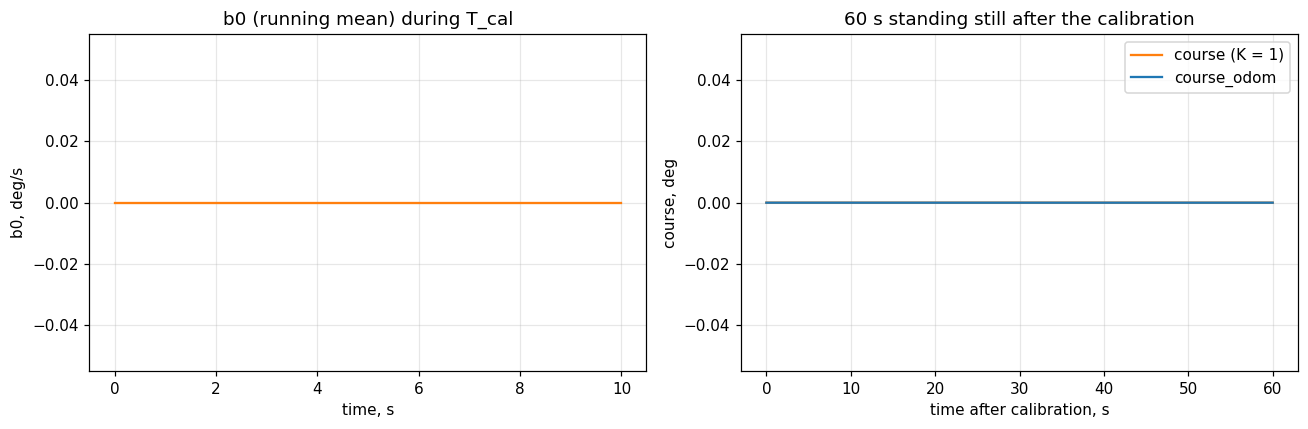

In [3]:
cal, after = static[static.stage == 0], static[static.stage == 1]
t = (after.t_ms - after.t_ms.iloc[0]) / 1000
slope = np.polyfit(t, deg(after.course), 1)[0] * 60          # deg/min, line fit
end = deg(after.course.iloc[-1]) * 60 / t.iloc[-1]            # deg/min, end value
n_cal = cal.ts.nunique()
print(f'b0 = {static.bias.iloc[-1] / 1000:.4f} deg/s from {n_cal} gyro samples in {cal.t_ms.iloc[-1] / 1000:.1f} s '
      f'(noise sigma {cal.gz.std() / 1000:.3f} deg/s -> standard error {cal.gz.std() / 1000 / np.sqrt(n_cal):.4f} deg/s)')
print(f'course drift: {slope:+.2f} deg/min (line fit), {end:+.2f} deg/min (end value) -> '
      + ('OK, below 1 deg/min' if abs(slope) < 1 and abs(end) < 1 else 'TOO LARGE: improve the calibration before the runs'))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(cal.t_ms / 1000, cal.bias / 1000, color=GYRO)
axes[0].set(title='b0 (running mean) during T_cal', xlabel='time, s', ylabel='b0, deg/s')
axes[1].plot(t, deg(after.course), color=GYRO, label='course (K = 1)')
axes[1].plot(t, deg(after.course_odom), color=ENC, label='course_odom')
axes[1].set(title='60 s standing still after the calibration', xlabel='time after calibration, s', ylabel='course, deg')
axes[1].legend()
plt.tight_layout()
plt.show()

## Step 4.1 - Reconstruct the three courses offline

`localize(d, K)` repeats the robot's Gyro angle, Odometry and Coordinates blocks on the logged raw sensors (`theta_l`, `theta_r`, `gz`, `bias`, `ts`).
It gives `course_odom`, the pure gyro course `course_gyro` and the filtered `course` for **any** `K`. With the run's own `K` it must give the logged course and pose.

In [4]:
def localize(d, K):
    moving = (d.stage == 1).to_numpy().copy()
    theta_l, theta_r = np.radians(d.theta_l), np.radians(d.theta_r)
    path = ((theta_r + theta_l) * r / 2).to_numpy()
    course_odom = ((theta_r - theta_l) * r / B).to_numpy()

    dt = (d.ts.diff().fillna(0) * TS_UNIT).clip(0, 1)
    gyro_inc = (GYRO_SIGN * np.radians((d.gz - d.bias) / 1000) / (1 + S_GYRO) * dt).to_numpy().copy()
    gyro_inc[~moving] = 0
    course_gyro = np.cumsum(gyro_inc)

    course = np.zeros(len(d))
    c = 0.0
    for k in np.flatnonzero(moving):
        c = K * (c + gyro_inc[k]) + (1 - K) * course_odom[k]       # the complementary filter
        course[k] = c

    dpath = np.diff(path, prepend=path[0])
    dpath[~moving] = 0
    return pd.DataFrame({'t': d.t_ms / 1000, 'i': d.i, 'moving': moving, 'path': path,
                         'x': np.cumsum(dpath * np.cos(course)), 'y': np.cumsum(dpath * np.sin(course)),
                         'course': course, 'course_odom': course_odom, 'course_gyro': course_gyro})

est = {run: localize(d, RUNS[run]) for run, d in logs.items()}
for run, d in logs.items():
    e, m = est[run], d.stage == 1
    err = np.abs(d.loc[m, ['course', 'x', 'y']].to_numpy() - e.loc[m, ['course', 'x', 'y']].to_numpy()).max(axis=0)
    print(f'K = {RUNS[run]}: largest difference offline - robot: course {deg(err[0]):.2e} deg, x {1000 * err[1]:.2e} mm, y {1000 * err[2]:.2e} mm')

K = 0.98: largest difference offline - robot: course 2.80e-13 deg, x 1.33e-12 mm, y 1.55e-12 mm
K = 0.5: largest difference offline - robot: course 1.53e-13 deg, x 1.55e-12 mm, y 1.44e-12 mm
K = 0.02: largest difference offline - robot: course 1.78e-13 deg, x 1.22e-12 mm, y 1.04e-12 mm


## Where was the disturbance?

The partner's stopwatch times go into `DISTURB` (seconds from program start: hold start, release). If they are left at `None`, the hand turn is found in the log:
during the turn the gyro sees about 45 deg that the encoders do not, so `course_gyro - course_odom` jumps. The hold itself (wheels spinning, robot not moving) cannot be seen in the sensors: gyro ~0 and equal wheel speeds look like driving straight. So the window is taken as 3 s of holding before the turn.

In [5]:
DISTURB = {'098': None, '050': None, '002': None}     # e.g. {'098': (24.0, 28.5), ...} from the stopwatch / video
HOLD_S = 3.0

def find_disturbance(e):
    m = e.moving.to_numpy()
    gap = pd.Series(deg(e.course_gyro - e.course_odom)[m].to_numpy(), index=e.t[m].to_numpy())
    n = max(1, int(round(1.0 / DT)))                            # change of the disagreement within 1 s
    jump = gap.diff(n).abs()
    if jump.max() < 15:
        return None                                             # no hand turn in this log
    t_end = jump.idxmax()
    return (t_end - 1.0 - HOLD_S, t_end)

for run in RUNS:
    if DISTURB[run] is None:
        DISTURB[run] = find_disturbance(est[run])
    w = DISTURB[run]
    seg = None if w is None else int(est[run].i[est[run].t >= w[0]].iloc[0])
    print(f'K = {RUNS[run]}: disturbance ' + ('not found' if w is None else f'{w[0]:.1f} - {w[1]:.1f} s, while driving to waypoint {seg}'))

K = 0.98: disturbance not found
K = 0.5: disturbance not found
K = 0.02: disturbance not found


## Step 4.2 - Course over time

For every run: `course_odom`, `course_gyro` and the filtered `course` (the robot's own), disturbance shaded.

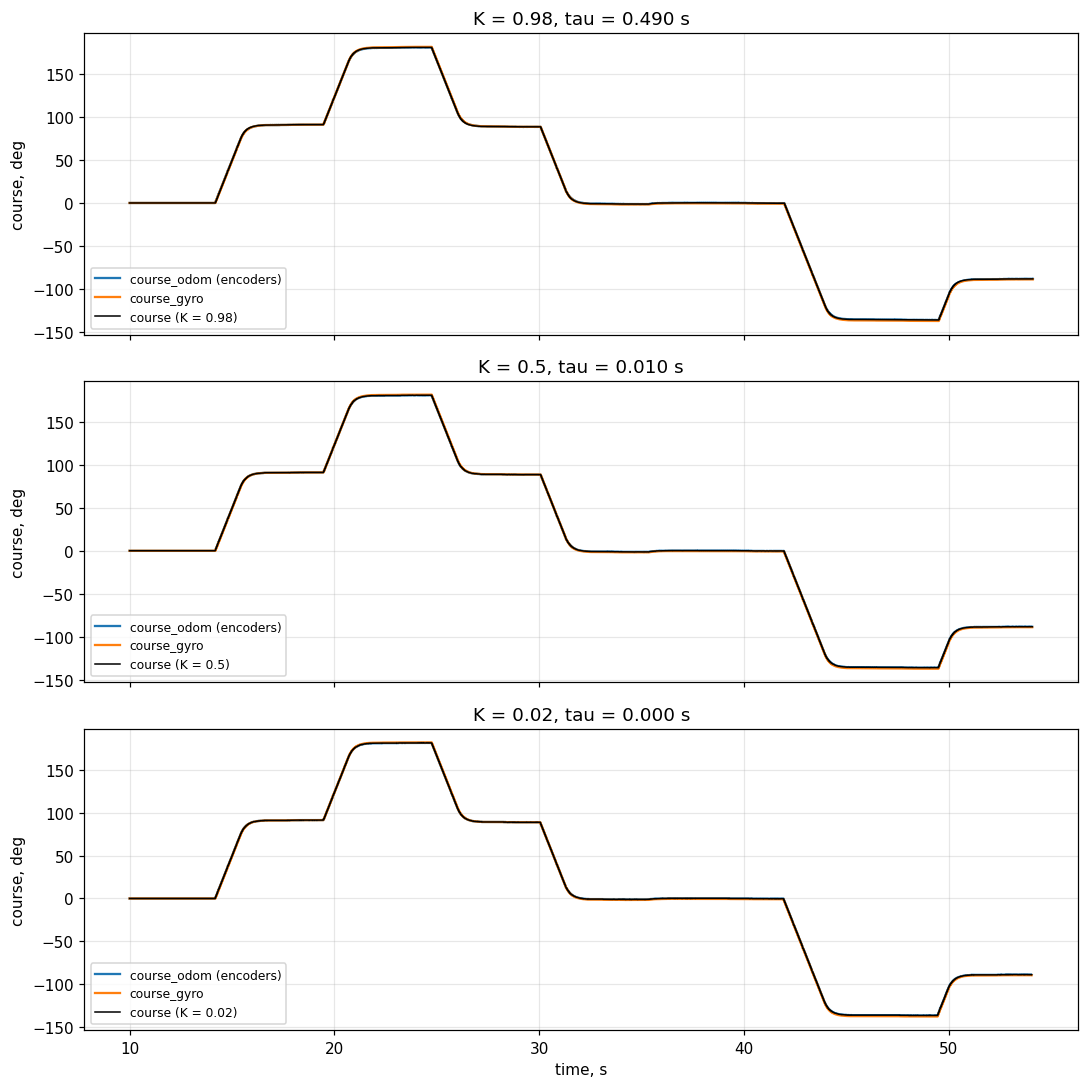

In [6]:
def shade(ax, run):
    if DISTURB[run] is not None:
        ax.axvspan(*DISTURB[run], color='gold', alpha=0.3, label='disturbance')

fig, axes = plt.subplots(3, 1, figsize=(10, 10), sharex=True)
for ax, run in zip(axes, RUNS):
    e = est[run][est[run].moving]
    ax.plot(e.t, deg(e.course_odom), color=ENC, label='course_odom (encoders)')
    ax.plot(e.t, deg(e.course_gyro), color=GYRO, label='course_gyro')
    ax.plot(e.t, deg(e.course), color=FILT, lw=1, label=f'course (K = {RUNS[run]})')
    shade(ax, run)
    ax.set(title=f'K = {RUNS[run]}, tau = {tau(RUNS[run]):.3f} s', ylabel='course, deg')
    ax.legend(loc='lower left', fontsize=8)
axes[-1].set_xlabel('time, s')
plt.tight_layout()
plt.show()

In [7]:
def recovery(e, w, K):
    # jump of each course across the disturbance, and how fast course returns to course_odom after it
    m = e.moving
    before, after = e[m & (e.t <= w[0])].iloc[-1], e[m & (e.t >= w[1])].iloc[0]
    gap = (e.course - e.course_odom)[m & (e.t >= w[1])]
    g0 = gap.iloc[0]
    if abs(deg(g0)) < 1:
        t_back = np.nan                                          # course already sits on course_odom
    else:
        back = gap.abs() < abs(g0) / np.e
        t_back = (e.t[back.index[back.to_numpy()][0]] - w[1]) if back.any() else np.inf
    return {'K': K, 'tau, s': round(tau(K), 3),
            'jump course_gyro, deg': round(deg(after.course_gyro - before.course_gyro), 1),
            'jump course_odom, deg': round(deg(after.course_odom - before.course_odom), 1),
            'jump course, deg': round(deg(after.course - before.course), 1),
            'course - course_odom at release, deg': round(deg(g0), 1),
            'time back to course_odom (1/e), s': round(t_back, 2)}

rows = {run: recovery(est[run], DISTURB[run], RUNS[run]) for run in RUNS if DISTURB[run] is not None}
pd.DataFrame(rows).T if rows else print('no disturbance in these logs (simulator)')

no disturbance in these logs (simulator)


## Step 4.3 - Trajectories

Left: the pose each robot **believed** (its own `K`). The controller drives this belief onto the waypoints, so after the disturbance it can look fine even when the robot drove off.
Right: the same runs replayed with the **pure gyro course** (`K = 1`). The gyro saw the hand turn, so this is the closest estimate of where the robot really went (path is still from the encoders, so the slipping during the hold is in both).

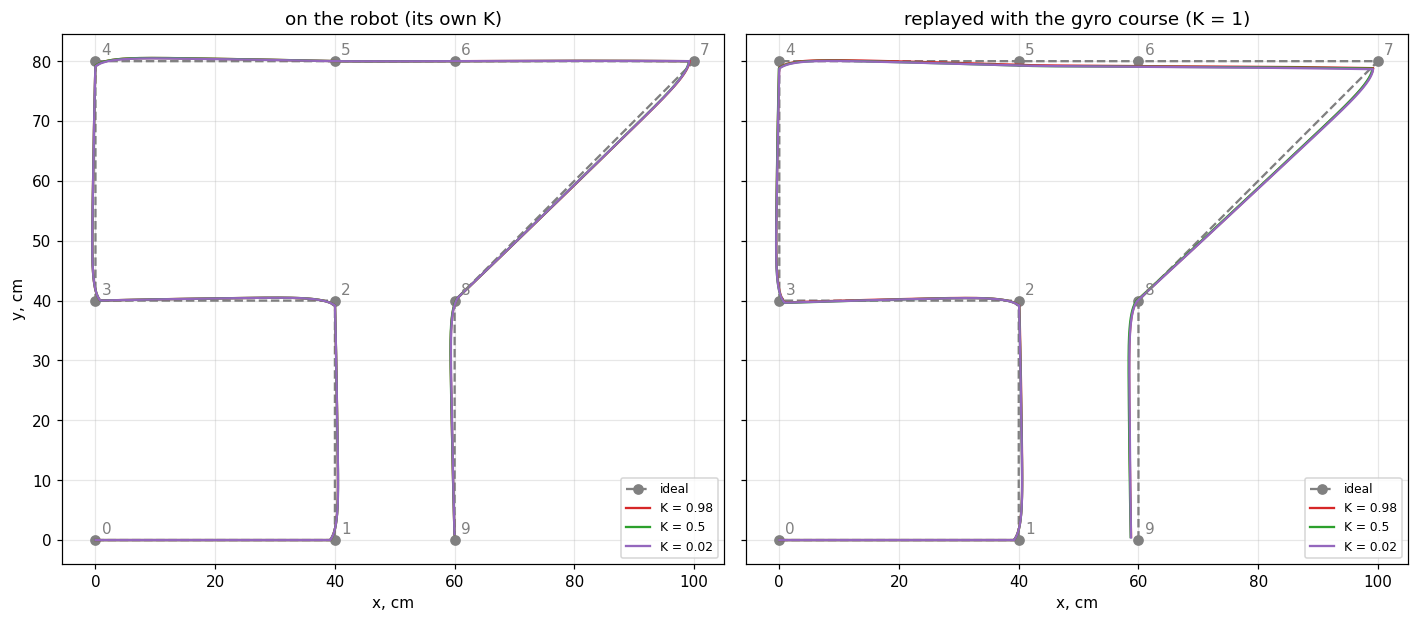

In [8]:
def draw_ideal(ax):
    ax.plot(100 * X_REF, 100 * Y_REF, 'o--', color=REF, label='ideal')
    for k in range(len(X_REF)):
        ax.annotate(k, (100 * X_REF[k], 100 * Y_REF[k]), xytext=(4, 4), textcoords='offset points', color=REF)

gyro_replay = {run: localize(d, 1.0) for run, d in logs.items()}
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharex=True, sharey=True)
for ax, src, title in ((axes[0], est, 'on the robot (its own K)'), (axes[1], gyro_replay, 'replayed with the gyro course (K = 1)')):
    draw_ideal(ax)
    for run in RUNS:
        e = src[run]
        ax.plot(100 * e.x, 100 * e.y, color=COL[run], label=f'K = {RUNS[run]}')
        if DISTURB[run] is not None:
            w = (e.t >= DISTURB[run][0]) & (e.t <= DISTURB[run][1])
            ax.plot(100 * e.x[w], 100 * e.y[w], color=COL[run], lw=5, alpha=0.4)
    ax.set(title=title, xlabel='x, cm', aspect='equal')
    ax.legend(fontsize=8)
axes[0].set_ylabel('y, cm')
plt.tight_layout()
plt.show()

## Step 4.4 - Comparison with the ideal trajectory

As in Labs 6-7: `distance` = signed sideways distance from the line of the segment being driven, `courseAngle` = course - `course_ref` of that segment (mean over the rows that **drive**, not the turns in place).
Final error = distance from the last pose to the last waypoint. Floor even with perfect sensors: the robot stops within `THRESHOLD` of every waypoint.

In [9]:
def turning(d):
    v, w = (d.control_r + d.control_l) / 2, (d.control_r - d.control_l) / 2
    return (d.stage == 1) & (w.abs() > v.abs())

BEHAVIOUR = {'098': 'fill in from the video', '050': 'fill in from the video', '002': 'fill in from the video'}

def metrics(d, e):
    m = e.moving
    k = (e.i - 1).clip(0, len(course_ref) - 1)
    dx, dy = np.diff(X_REF)[k], np.diff(Y_REF)[k]
    dist = (dx * (e.y - Y_REF[k]) - dy * (e.x - X_REF[k])) / np.hypot(dx, dy)
    drive = m & ~turning(d)
    ca = wrap(e.course - course_ref[k])
    end = e.iloc[-1]
    return {'max |distance|, cm': round(100 * dist[m].abs().max(), 1),
            'RMS distance, cm': round(100 * np.sqrt((dist[m] ** 2).mean()), 1),
            'mean |courseAngle|, deg': round(deg(ca[drive].abs().mean()), 1),
            'final error, cm': round(100 * np.hypot(end.x - X_REF[-1], end.y - Y_REF[-1]), 1)}

def summary(src):
    return pd.DataFrame([{'Run': n + 1, 'K': RUNS[run], 'tau, s': round(tau(RUNS[run]), 3), **metrics(logs[run], src[run]),
                          'behaviour after the disturbance': BEHAVIOUR[run]} for n, run in enumerate(RUNS)]).set_index('Run')

print('Estimate on the robot (what each robot believed):')
display(summary(est))
print('Replayed with the gyro course (closest to what really happened):')
display(summary(gyro_replay).drop(columns='behaviour after the disturbance'))

Estimate on the robot (what each robot believed):


,K,"tau, s","max |distance|, cm","RMS distance, cm","mean |courseAngle|, deg","final error, cm",behaviour after the disturbance
Run,,,,,,,
1,0.98,0.49,1.0,0.4,1.2,1.0,fill in from the video
2,0.50,0.01,1.0,0.4,1.3,1.0,fill in from the video
3,0.02,0.00,1.0,0.4,1.2,1.0,fill in from the video


Replayed with the gyro course (closest to what really happened):


,K,"tau, s","max |distance|, cm","RMS distance, cm","mean |courseAngle|, deg","final error, cm"
Run,,,,,,
1,0.98,0.49,1.6,0.7,1.5,1.4
2,0.50,0.01,1.7,0.8,1.5,1.4
3,0.02,0.00,1.5,0.8,1.5,1.3


## Step 4.5 - What-if: other `K` on the log of run 1

The log of run 1 (`K = 0.98`) is replayed with other gains. Which `K` keeps the hand turn in the estimate for at least 5 s?
"Keeps" = `course - course_odom` stays above `1/e` of its value at the release for that long, which is the time constant `τ`.
Note: offline, the robot's motion stays the one of run 1; with another `K` on the robot the controller would have reacted differently.

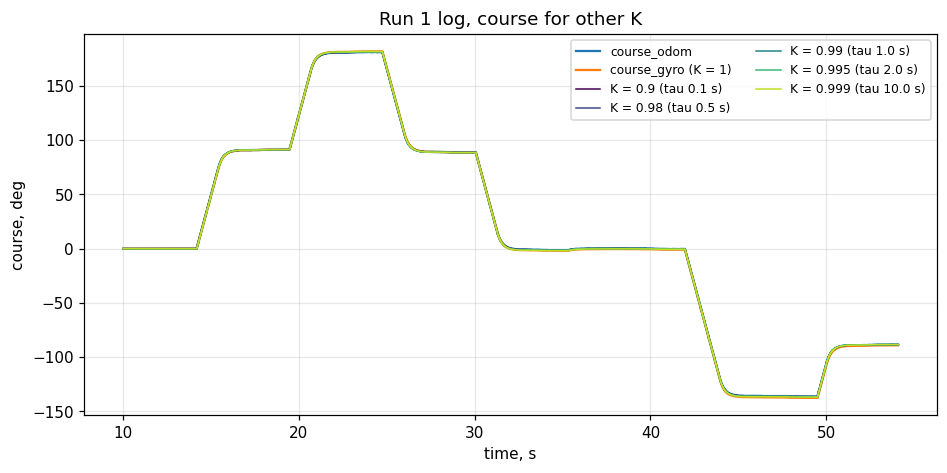

tau >= 5 s needs K >= 5 / (5 + dt) = 0.9980 at dt = 10 ms


In [10]:
WHATIF = [0.9, 0.98, 0.99, 0.995, 0.999]
d = logs['098']
w = DISTURB['098']
fig, ax = plt.subplots(figsize=(10, 4.5))
e1 = localize(d, 1.0)
m = e1.moving
ax.plot(e1.t[m], deg(e1.course_odom[m]), color=ENC, label='course_odom')
ax.plot(e1.t[m], deg(e1.course_gyro[m]), color=GYRO, label='course_gyro (K = 1)')
rows = []
for K, c in zip(WHATIF, plt.cm.viridis(np.linspace(0, 0.9, len(WHATIF)))):
    e = localize(d, K)
    ax.plot(e.t[m], deg(e.course[m]), color=c, lw=1, label=f'K = {K} (tau {tau(K):.1f} s)')
    if w is not None:
        rows.append(recovery(e, w, K))
if w is not None:
    ax.axvspan(*w, color='gold', alpha=0.3, label='disturbance')
    ax.set_xlim(w[0] - 3, min(e1.t.iloc[-1], w[1] + 20))
ax.set(xlabel='time, s', ylabel='course, deg', title='Run 1 log, course for other K')
ax.legend(fontsize=8, ncol=2)
plt.show()

K5 = 5 / (5 + DT)
print(f'tau >= 5 s needs K >= 5 / (5 + dt) = {K5:.4f} at dt = {1000 * DT:.0f} ms')
pd.DataFrame(rows).set_index('K')[['tau, s', 'course - course_odom at release, deg', 'time back to course_odom (1/e), s']] if rows else None

## Short analysis

*Fill in with the numbers above and what the videos show (6-10 sentences).*

1. **How did the robot act after the disturbance with each `K`? Did it notice the turn, and did it correct it?**
   K = 0.98: the gyro saw the ~45 deg hand turn, so `course` jumped and the controller turned back toward the waypoint; then `course` slid back to `course_odom` within a few `τ` ... K = 0.5 / 0.02: ...

2. **Why do runs 2 and 3 behave almost the same?**
   At dt = ... ms, `τ` = ... s (K = 0.5) and ... s (K = 0.02): both far shorter than one control cycle's worth of motion, so the gyro part is forgotten within one or two cycles and `course` = `course_odom` in both. The hand turn is mostly not seen by the encoders (the wheels do not roll when the robot is rotated by hand) ...

3. **Holding the robot made the wheels slip. Which part of the estimate did that corrupt (`path` or `course`)? Can the complementary filter fix it?**
   `path`: the encoders counted wheel rotation while the robot stood, so x, y moved forward in the estimate by about ... cm. The course is not hurt (both wheels slip equally, the gyro sees no rotation). The filter only blends two **course** sources; `path` comes from the encoders alone, so it cannot fix this.

4. **Which `K` would you choose for this robot, and why? What does a fixed `K` miss, which the Kalman filter in Week 12 will adapt?**
   Large `K` (τ of a few seconds, e.g. 0.98-0.99 at our dt): fast and slip-free from the gyro, while the bias (calibration check: ... deg/min) is pulled back by the encoders over τ ... A fixed `K` trusts both sensors the same at all times; a Kalman filter weights them by their current uncertainty (encoders bad while turning / slipping, gyro bad over long times) and computes the gain every cycle.